# Fig. 1. Study area, stations and data availability
(a) Bogotá and Medellín with the ERA5 boxes and the fire-source geometry; (b) the RMCAB stations of Bogotá
(positions digitised from Bustos et al. 2026, Fig. 1; see `A0_station_locations`); (c) data availability.
**Edit the settings cell to change markers, sizes, colours and labels.** Medellín has no station map because
no coordinate list is available for its stations.

In [1]:
# Setup
import sys
from pathlib import Path
HERE = Path.cwd().resolve()
sys.path.insert(0, str(HERE.parent)); sys.path.insert(0, str(HERE.parents[1]))
import numpy as np, pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Rectangle
from matplotlib.lines import Line2D
import cartopy.crs as ccrs, cartopy.feature as cf
from cartopy.geodesic import Geodesic
from style import *
from common.external_data import (BOGOTA_LAT, BOGOTA_LON, MEDELLIN_LAT, MEDELLIN_LON, BOGOTA_ERA5_AREA,
                                  MEDELLIN_ERA5_AREA, FIRE_SOURCE_REGIONS)

In [2]:
# Settings (edit here)
S = dict(
    # Portrait layout (2026-09-22, readability fix): panel (a) full width on top, (b)/(c) side by side below --
    # journal pages are taller than wide, and all three panels are themselves tall/narrow (Bogotá's extent,
    # the 15-row matrix), so a stacked layout reads better than the original 1x3 row.
    figsize=(8.6, 9.8), save_name="fig01_study_area_monitoring", save=True,
    row_heights=[0.78, 1.15], hspace=0.28,
    width_ratios=[0.85, 1.15], wspace=0.55,
    # --- stations (panel b) ---
    station_marker="^",                 # any matplotlib marker: "^", "o", "s", "D", "v", "P" ...
    station_size_range=(70, 240),       # marker area (points^2) for 0 -> max years in the O3 network
    size_by="o3_years_used",            # column that sets marker size ("o3_years_used", "pm25_years_used" or None for constant)
    station_size_const=110,
    color_by="pm25_years_used",         # column that sets marker colour
    station_cmap="YlOrBr",
    station_edgecolor=NAVY, station_linewidth=0.9,
    # 2026-10-06 (user: remove the locality names in panel b, keep only the triangles)
    label_stations=False, label_fontsize=6.6, label_color=NAVY,
    label_names={"Centro de alto rendimiento": "CAR", "Carvajal-Sevillana": "Carvajal", "Móvil Fontibón": "Móvil Fontibón"},   # shorter labels; "Alto rend. (CAR)" clipped against the map's east edge in the narrower portrait column
    # Colour and size need two separate legends; a vertical colorbar in the b/c gutter plus one size
    # legend below the map (rather than both stacked below it) is what avoids every collision tried so far.
    colorbar_orientation="vertical", size_legend_loc="upper center", size_legend_anchor=(0.5, -0.06),
    label_offsets={"Fontibón": (-4, 5), "Móvil Fontibón": (-4, -8), "Puente Aranda": (-6, 4), "Carvajal-Sevillana": (-4, -9),
                   "Tunal": (5, -7), "Centro de alto rendimiento": (6, 2), "Kennedy": (-5, 4), "Ciudad Bolívar": (-5, -9),
                   "Bolivia": (-4, 5), "Colina": (5, 3), "Suba": (-4, 6), "Guaymaral": (-5, 5), "Usaquén": (-5, 5),
                   "Las Ferias": (5, 2), "MinAmbiente": (5, -8), "San Cristóbal": (5, -8), "El Jazmín": (5, 3), "Usme": (5, -8)},
    bogota_extent=(-74.215, -74.005, 4.505, 4.815),     # lon0, lon1, lat0, lat1 (widening this to fix east-edge clipping just compressed and crowded the west-side station cluster instead -- fixed per-label below)
    use_osm_tiles=False, osm_zoom=12,                   # True draws OpenStreetMap tiles (needs internet; credit "(c) OpenStreetMap contributors")
    bogota_shape_path=ROOT / "depto_WGS84.shp",         # Bogota D.C. boundary (DPTO '11'), already in the project root, WGS84
    bogota_shape_facecolor="#FAFAF7", bogota_shape_edgecolor=NAVY, bogota_shape_lw=1.2,
    # --- regional map (panel a) ---
    regional_extent=(-83, -62, -5, 13),
    city_marker="o", city_marker_size=6, era5_box_alpha=1.0,
    sector_alpha=0.22, sector_color=PM25, sector_radius_km=1500,
    fire_region_labels={"caqueta": "Caquetá", "magdalena_valley": "Magdalena Valley", "nevados": "Nevados"},   # R8: capitalised
    fire_region_label_offsets={"magdalena_valley": (16, 10)},    # points; nudges the label clear of the Medellín east-sector wedge
    bogota_elevation_m=2600,   # R8: 2550 -> 2600 (commonly quoted RMCAB elevation)
    # --- availability matrix (panel c) ---
    matrix_cmap="Blues", matrix_fontsize=6.8,
    panel_label_size=11,
)

In [3]:
# Load the stations, the data inventory, and Bogota's real boundary
st = pd.read_csv(DATA_OUT / "bogota_stations_digitised.csv")
inv = pd.read_csv(DATA_OUT / "table1_data_inventory.csv").set_index("variable")
# Real city shape (2026-09-23, user request), not a generic land fill: IGAC/DANE department polygon
# already in the project (depto_WGS84.shp), DPTO '11' = Bogota D.C. Already WGS84 degrees, no reprojection needed.
bogota_shape = gpd.read_file(S["bogota_shape_path"])
bogota_shape = bogota_shape.loc[bogota_shape.DPTO == "11", "geometry"].iloc[0]
st[["station", "lat", "lon", "pm25_years_used", "o3_years_used"]].round(4)

,station,lat,lon,pm25_years_used,o3_years_used
0,Bolivia,4.7355,-74.1267,4,1
1,Carvajal-Sevillana,4.5953,-74.1490,8,7
2,Centro de alto rendimiento,4.6582,-74.0849,11,6
3,Ciudad Bolívar,4.5778,-74.1671,5,2
4,Colina,4.7370,-74.0702,4,1
5,El Jazmín,4.6084,-74.1155,5,2
6,Fontibón,4.6787,-74.1440,7,4
7,Guaymaral,4.7836,-74.0442,11,10
8,Kennedy,4.6253,-74.1616,12,7
9,Las Ferias,4.6901,-74.0827,12,8


saved /path/to/project/Paper/figures/fig01_study_area_monitoring.png


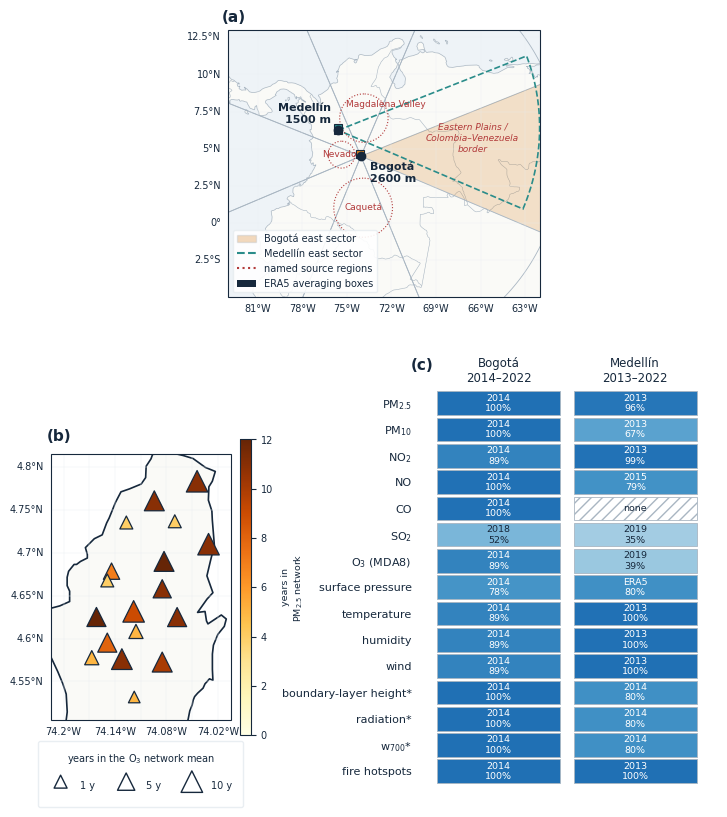

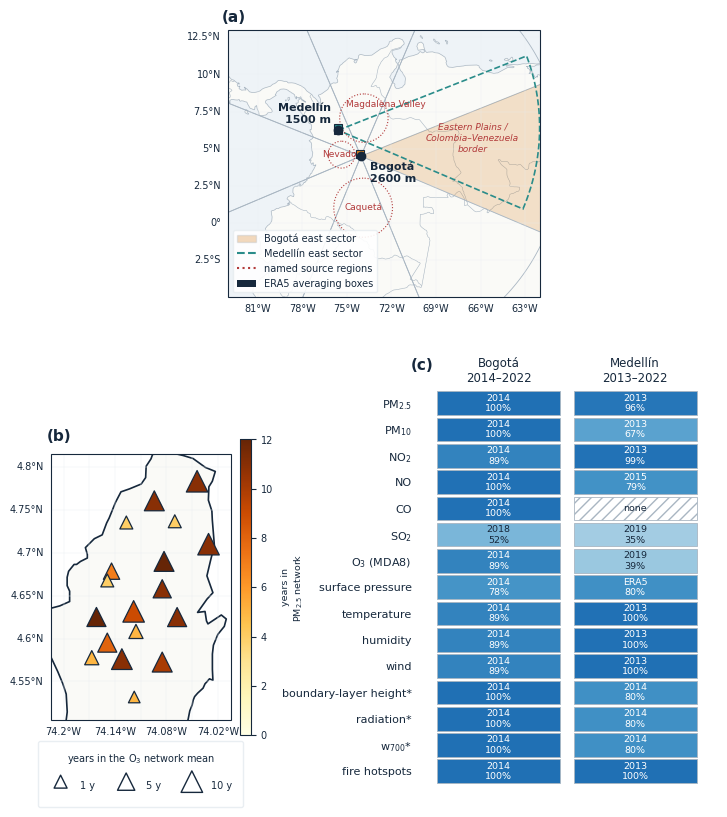

In [4]:
# Figure
geod = Geodesic()
def wedge(lat, lon, b0, b1, r_km, n=50):
    pts = geod.direct(np.tile([lon, lat], (n, 1)), np.linspace(b0, b1, n), np.full(n, r_km * 1000.0))[:, :2]
    return np.vstack([[lon, lat], pts])

fig = plt.figure(figsize=S["figsize"])
gs = fig.add_gridspec(2, 2, height_ratios=S["row_heights"], hspace=S["hspace"], width_ratios=S["width_ratios"], wspace=S["wspace"])

# ---- (a) regional context, full width on top --------------------------------
ax = fig.add_subplot(gs[0, :], projection=ccrs.PlateCarree())
ax.set_extent([S["regional_extent"][0], S["regional_extent"][1], S["regional_extent"][2], S["regional_extent"][3]], crs=ccrs.PlateCarree())
ax.add_feature(cf.OCEAN.with_scale("50m"), facecolor="#EEF3F7", zorder=0); ax.add_feature(cf.LAND.with_scale("50m"), facecolor="#FAFAF7", zorder=0)
ax.add_feature(cf.COASTLINE.with_scale("50m"), lw=0.5, edgecolor=GREY, zorder=1); ax.add_feature(cf.BORDERS.with_scale("50m"), lw=0.4, edgecolor=GREY, zorder=1)
names = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
for i, nm in enumerate(names):
    poly = wedge(BOGOTA_LAT, BOGOTA_LON, i * 45 - 22.5, i * 45 + 22.5, S["sector_radius_km"])
    ax.add_patch(Polygon(poly, transform=ccrs.PlateCarree(), facecolor=S["sector_color"] if nm == "E" else "none",
                         alpha=S["sector_alpha"] if nm == "E" else 1, edgecolor=GREY, lw=0.6, zorder=2))
# 2026-09-28 (user: nothing names what's physically out there in the east sector): a text label on the
# wedge itself, not a new circle -- the named circles that used to sit here (cvb, eastern_plains) were
# deliberately removed (see FIRE_SOURCE_REGIONS' docstring below) for being collinear/redundant with each
# other, not because the region doesn't matter; a label keeps that context without reintroducing them.
# 2026-09-28 (user: colour this like the other named source regions): it plays the same role as the
# red dotted circles (Caqueta, Magdalena Valley, Nevados) in the fire-attribution analysis, just drawn
# as a label on the wedge instead of a circle -- see the caption for why it isn't circled.
ax.annotate("Eastern Plains /\nColombia–Venezuela\nborder", (BOGOTA_LON + 7.5, BOGOTA_LAT + 1.2), transform=ccrs.PlateCarree(),
           fontsize=6.5, color=RED, ha="center", va="center", style="italic", zorder=4, linespacing=1.3)
ax.add_patch(Polygon(wedge(MEDELLIN_LAT, MEDELLIN_LON, 67.5, 112.5, S["sector_radius_km"]), transform=ccrs.PlateCarree(),
                     facecolor="none", edgecolor=O3, lw=1.2, ls="--", zorder=3))
for nm, cfg in FIRE_SOURCE_REGIONS.items():
    ax.add_patch(Polygon(geod.circle(cfg["lon"], cfg["lat"], cfg["radius_km"] * 1000.0, n_samples=80), transform=ccrs.PlateCarree(),
                         facecolor="none", edgecolor=RED, lw=0.8, ls=":", zorder=3))
    dx, dy = S["fire_region_label_offsets"].get(nm, (0, 0))
    ax.annotate(S["fire_region_labels"].get(nm, nm.replace("_", " ")), (cfg["lon"], cfg["lat"]), xytext=(dx, dy), textcoords="offset points",
               transform=ccrs.PlateCarree(), fontsize=6.5, color=RED, ha="center", va="center", zorder=4)
for area, col in [(BOGOTA_ERA5_AREA, PM25), (MEDELLIN_ERA5_AREA, O3)]:
    n, w, s_, e = area
    ax.add_patch(Rectangle((w, s_), e - w, n - s_, transform=ccrs.PlateCarree(), facecolor=col, edgecolor=NAVY, lw=0.8, alpha=S["era5_box_alpha"], zorder=5))
for lon, lat in [(BOGOTA_LON, BOGOTA_LAT), (MEDELLIN_LON, MEDELLIN_LAT)]:
    ax.plot(lon, lat, S["city_marker"], ms=S["city_marker_size"], color=NAVY, transform=ccrs.PlateCarree(), zorder=6)
ax.text(BOGOTA_LON + 0.6, BOGOTA_LAT - 1.7, f"Bogotá\n{S['bogota_elevation_m']} m", transform=ccrs.PlateCarree(), fontsize=8, fontweight="bold")
ax.text(MEDELLIN_LON - 0.5, MEDELLIN_LAT + 0.5, "Medellín\n1500 m", transform=ccrs.PlateCarree(), fontsize=8, fontweight="bold", ha="right")
ax.legend(handles=[Rectangle((0, 0), 1, 1, facecolor=S["sector_color"], alpha=0.3, edgecolor=GREY, label="Bogotá east sector"),
                   Line2D([], [], color=O3, ls="--", label="Medellín east sector"),
                   Line2D([], [], color=RED, ls=":", label="named source regions"),
                   Rectangle((0, 0), 1, 1, facecolor=NAVY, label="ERA5 averaging boxes")], loc="lower left", fontsize=7, framealpha=0.9, edgecolor=LIGHT)
gl = ax.gridlines(draw_labels=True, lw=0.3, color=LIGHT, alpha=0.8); gl.top_labels = gl.right_labels = False; gl.xlabel_style = gl.ylabel_style = dict(size=7)
ax.text(-0.02, 1.03, "(a)", transform=ax.transAxes, fontsize=S["panel_label_size"], fontweight="bold")

# ---- (b) Bogota stations, bottom left ----------------------------------------------
axb = fig.add_subplot(gs[1, 0], projection=ccrs.PlateCarree())
lon0, lon1, lat0, lat1 = S["bogota_extent"]
axb.set_extent([lon0, lon1, lat0, lat1], crs=ccrs.PlateCarree())
if S["use_osm_tiles"]:
    import cartopy.io.img_tiles as cimgt
    axb.add_image(cimgt.OSM(), S["osm_zoom"], alpha=0.6)
else:
    axb.add_geometries([bogota_shape], crs=ccrs.PlateCarree(), facecolor=S["bogota_shape_facecolor"],
                       edgecolor=S["bogota_shape_edgecolor"], linewidth=S["bogota_shape_lw"], zorder=0)
    axb.add_feature(cf.RIVERS.with_scale("10m"), edgecolor="#BFD3E6", lw=0.6, zorder=1)
if S["size_by"]:
    v = st[S["size_by"]].to_numpy(float); smin, smax = S["station_size_range"]; sizes = smin + (smax - smin) * v / max(v.max(), 1)
else:
    sizes = np.full(len(st), S["station_size_const"])
cvals = st[S["color_by"]].to_numpy(float)
sc = axb.scatter(st.lon, st.lat, s=sizes, c=cvals, cmap=S["station_cmap"], vmin=0, vmax=cvals.max(), marker=S["station_marker"],
                 edgecolors=S["station_edgecolor"], linewidths=S["station_linewidth"], transform=ccrs.PlateCarree(), zorder=5)
if S["label_stations"]:
    for r in st.itertuples():
        dx, dy = S["label_offsets"].get(r.station, (5, 3))
        axb.annotate(S["label_names"].get(r.station, r.station), (r.lon, r.lat), xytext=(dx, dy), textcoords="offset points", fontsize=S["label_fontsize"], color=S["label_color"],
                     ha="left" if dx >= 0 else "right", va="bottom" if dy >= 0 else "top", zorder=6, transform=ccrs.PlateCarree())
axb.plot(BOGOTA_LON, BOGOTA_LAT, "x", color=GREY, ms=5, transform=ccrs.PlateCarree(), zorder=2)
cb = fig.colorbar(sc, ax=axb, orientation=S["colorbar_orientation"], shrink=0.75, pad=0.04, aspect=26)
cb.ax.tick_params(labelsize=7)
# 2026-09-28 (user: colorbar needs a label): the earlier attempt used a full rotated label that collided
# with panel (c)'s row labels; a short two-line label at a smaller size clears them.
cb.set_label("years in\nPM$_{2.5}$ network", fontsize=6.8, labelpad=6)
if S["size_by"]:
    for yrs in (1, 5, 10):
        axb.scatter([], [], s=S["station_size_range"][0] + (S["station_size_range"][1] - S["station_size_range"][0]) * yrs / max(st[S["size_by"]].max(), 1),
                    marker=S["station_marker"], facecolor="none", edgecolor=NAVY, label=f"{yrs} y")
    # handleheight/handlelength default to ~0.7/2.0 fontsize-units, far too small for a marker this large
    # (s up to station_size_range[1] -> ~17pt diameter) -- it was overflowing the legend frame (2026-09-23).
    axb.legend(title="years in the O$_3$ network mean", fontsize=7, title_fontsize=7, loc=S["size_legend_loc"], bbox_to_anchor=S["size_legend_anchor"],
              ncol=3, framealpha=0.92, edgecolor=LIGHT, labelspacing=1.1, handleheight=2.8, handlelength=2.4, borderpad=1.1)
gl = axb.gridlines(draw_labels=True, lw=0.3, color=LIGHT); gl.top_labels = gl.right_labels = False; gl.xlabel_style = gl.ylabel_style = dict(size=7)
axb.text(-0.02, 1.05, "(b)", transform=axb.transAxes, fontsize=S["panel_label_size"], fontweight="bold")
# Provenance ("positions digitised from Bustos et al...") and the cell-reading note below are in the
# caption (Paper/figure_titles_and_legends.md), not on the plot -- readability fix, 2026-09-22.

# ---- (c) availability matrix, bottom right -----------------------------------------
axc = fig.add_subplot(gs[1, 1])
rows = [("pm25", "PM$_{2.5}$"), ("pm10", "PM$_{10}$"), ("no2", "NO$_2$"), ("no", "NO"), ("co", "CO"), ("so2", "SO$_2$"), ("o3", "O$_3$ (MDA8)"),
        ("pressure", "surface pressure"), ("temp_2m", "temperature"), ("rh_2m", "humidity"), ("wind_speed", "wind"),
        ("blh_mean", "boundary-layer height*"), ("radiation_mean", "radiation*"), ("w700", "w$_{700}$*"), ("hotspots_sector_E", "fire hotspots")]
# * ERA5 reanalysis (stated once in the caption rather than on every row -- the full names were long
# enough to overflow into panel (b) in the portrait layout).
cmap = plt.get_cmap(S["matrix_cmap"])
for i, (v, lab) in enumerate(rows):
    for j, city in enumerate(["Bogota", "Medellin"]):
        pct = inv.loc[v, f"{city}_completeness_pct"]; first = inv.loc[v, f"{city}_first"]
        txt = "none" if pct == 0 else f"{str(first)[:4]}\n{pct:.0f}%"
        if v == "pressure" and city == "Medellin": txt = f"ERA5\n{pct:.0f}%"
        axc.add_patch(Rectangle((j - 0.45, i - 0.45), 0.9, 0.9, facecolor="white" if pct == 0 else cmap(0.15 + 0.6 * pct / 100), edgecolor=GREY, lw=0.6,
                                hatch="///" if pct == 0 else None))
        axc.text(j, i, txt, ha="center", va="center", fontsize=S["matrix_fontsize"], color="white" if pct > 65 else NAVY)
axc.set_xlim(-0.6, 1.6); axc.set_ylim(len(rows) - 0.5, -0.5)
axc.set_xticks([0, 1]); axc.set_xticklabels(["Bogotá\n2014–2022", "Medellín\n2013–2022"], fontsize=8.5)
axc.xaxis.tick_top(); axc.set_yticks(range(len(rows))); axc.set_yticklabels([l for _, l in rows], fontsize=8)
axc.tick_params(length=0); [sp.set_visible(False) for sp in axc.spines.values()]
axc.text(-0.02, 1.05, "(c)", transform=axc.transAxes, fontsize=S["panel_label_size"], fontweight="bold")
if S["save"]: save_fig(fig, S["save_name"])
fig